# 05 · Convolutional Neural Network

A dense layer on an image treats every pixel as unrelated and must re-learn a pattern at each location. A **convolution** slides one small filter over the image, reusing the same weights everywhere:
$$\text{out}[c_o,i,j]=b_{c_o}+\sum_{c_i,u,v} W[c_o,c_i,u,v]\;x[c_i,\,i+u,\,j+v]$$

**im2col** turns every sliding window into a column, so the whole convolution becomes *one matrix multiply* `W_col @ cols` instead of nested loops. Backward is the transpose trick: `grad_cols = W_colᵀ @ grad_out`, scattered back with **col2im** (overlapping windows add up).

**Max-pool** keeps the largest value in each window (gradient flows only to the winner). **Global max-pool** takes the max over *all* positions: a feature detected anywhere gives the same output — true translation invariance.

## The experiment
Classify **square vs plus-sign** stamped at a random position. Train on shapes in the **left** part of the canvas, test on shapes in a **disjoint right** region. A model that memorizes pixel locations (MLP) can't transfer; a CNN with shared filters + global pooling can.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## im2col / col2im

In [2]:
def get_im2col_indices(x_shape, field_h, field_w, stride=1):
    N, C, H, W = x_shape
    out_h = (H - field_h) // stride + 1
    out_w = (W - field_w) // stride + 1

    i0 = np.repeat(np.arange(field_h), field_w)
    i0 = np.tile(i0, C)
    i1 = stride * np.repeat(np.arange(out_h), out_w)
    j0 = np.tile(np.arange(field_w), field_h * C)
    j1 = stride * np.tile(np.arange(out_w), out_h)
    i = i0.reshape(-1, 1) + i1.reshape(1, -1)
    j = j0.reshape(-1, 1) + j1.reshape(1, -1)
    k = np.repeat(np.arange(C), field_h * field_w).reshape(-1, 1)
    return k, i, j

In [3]:
def im2col(x, field_h, field_w, stride=1):
    k, i, j = get_im2col_indices(x.shape, field_h, field_w, stride)
    C = x.shape[1]
    cols = x[:, k, i, j]  # (N, C*field_h*field_w, out_h*out_w)
    cols = cols.transpose(1, 2, 0).reshape(field_h * field_w * C, -1)
    return cols

In [4]:
def col2im(cols, x_shape, field_h, field_w, stride=1):
    N, C, H, W = x_shape
    x_grad = np.zeros(x_shape, dtype=cols.dtype)
    k, i, j = get_im2col_indices(x_shape, field_h, field_w, stride)
    cols_reshaped = cols.reshape(C * field_h * field_w, -1, N).transpose(2, 0, 1)
    np.add.at(x_grad, (slice(None), k, i, j), cols_reshaped)
    return x_grad

## Layers

In [5]:
class Conv2D:
    has_params = True

    def __init__(self, in_channels, out_channels, kernel_size, l2=0.0):
        self.k = kernel_size
        self.cout = out_channels
        scale = np.sqrt(2.0 / (in_channels * kernel_size * kernel_size))
        self.weights = np.random.randn(out_channels, in_channels, kernel_size, kernel_size) * scale
        self.bias = np.zeros((out_channels, 1))
        self.l2 = l2
        self.cache = None

    def forward(self, x, training=True):
        N, Cin, H, W = x.shape
        k = self.k
        out_h, out_w = H - k + 1, W - k + 1
        cols = im2col(x, k, k, stride=1)  # (Cin*k*k, out_h*out_w*N)
        w_col = self.weights.reshape(self.cout, -1)
        out = w_col @ cols + self.bias
        out = out.reshape(self.cout, out_h, out_w, N).transpose(3, 0, 1, 2)
        self.cache = (x.shape, cols)
        return out

    def backward(self, grad_output, lr):
        x_shape, cols = self.cache
        k = self.k
        grad_out_flat = grad_output.transpose(1, 2, 3, 0).reshape(self.cout, -1)

        grad_weights = (grad_out_flat @ cols.T).reshape(self.weights.shape) + self.l2 * self.weights
        grad_bias = grad_out_flat.sum(axis=1, keepdims=True)

        w_col = self.weights.reshape(self.cout, -1)
        grad_cols = w_col.T @ grad_out_flat
        grad_input = col2im(grad_cols, x_shape, k, k, stride=1)

        self.weights -= lr * grad_weights
        self.bias -= lr * grad_bias
        return grad_input

In [6]:
class MaxPool2D:
    has_params = False

    def __init__(self, size=2):
        self.size = size
        self.cache = None

    def forward(self, x, training=True):
        N, C, H, W = x.shape
        s = self.size
        out_h, out_w = H // s, W // s
        x_r = x[:, :, :out_h * s, :out_w * s].reshape(N, C, out_h, s, out_w, s)
        out = x_r.max(axis=(3, 5))
        self.cache = (x_r, out)
        return out

    def backward(self, grad_output):
        x_r, out = self.cache
        mask = (x_r == out[:, :, :, None, :, None])
        counts = mask.sum(axis=(3, 5), keepdims=True)  # split gradient evenly on ties
        grad = mask * (grad_output[:, :, :, None, :, None] / counts)
        N, C, out_h, s1, out_w, s2 = x_r.shape
        return grad.reshape(N, C, out_h * s1, out_w * s2)

In [7]:
class GlobalMaxPool:
    """Collapses (N,C,H,W) -> (N,C) by taking the max over all spatial positions.

    This is what makes the CNN translation-invariant: a shape detected
    anywhere in the feature map produces the same output vector.
    """

    has_params = False

    def forward(self, x, training=True):
        N, C, H, W = x.shape
        self.shape = x.shape
        flat = x.reshape(N, C, H * W)
        out = flat.max(axis=2)
        mask = (flat == out[:, :, None])
        counts = mask.sum(axis=2, keepdims=True)
        self.mask = mask / counts
        return out

    def backward(self, grad_output):
        N, C, H, W = self.shape
        return (self.mask * grad_output[:, :, None]).reshape(N, C, H, W)

In [8]:
class Flatten:
    has_params = False

    def forward(self, x, training=True):
        self.shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, grad_output):
        return grad_output.reshape(self.shape)

In [9]:
class Dense:
    has_params = True

    def __init__(self, input_dim, output_dim):
        self.weights = np.random.randn(input_dim, output_dim) * np.sqrt(2.0 / input_dim)
        self.bias = np.zeros((1, output_dim))
        self.input = None

    def forward(self, x, training=True):
        self.input = x
        return np.dot(x, self.weights) + self.bias

    def backward(self, grad_output, lr):
        grad_weights = np.dot(self.input.T, grad_output)
        grad_bias = np.sum(grad_output, axis=0, keepdims=True)
        grad_input = np.dot(grad_output, self.weights.T)
        self.weights -= lr * grad_weights
        self.bias -= lr * grad_bias
        return grad_input

In [10]:
class ReLU:
    has_params = False

    def forward(self, x, training=True):
        self.input = x
        return np.maximum(0, x)

    def backward(self, grad_output):
        return grad_output * (self.input > 0).astype(float)

In [11]:
class Sigmoid:
    has_params = False

    def forward(self, x, training=True):
        self.output = 1 / (1 + np.exp(-x))
        return self.output

    def backward(self, grad_output):
        return grad_output * self.output * (1 - self.output)

In [12]:
class BCELoss:
    def forward(self, y_pred, y_true):
        eps = 1e-15
        yp = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(yp) + (1 - y_true) * np.log(1 - yp))

    def backward(self, y_pred, y_true):
        eps = 1e-15
        yp = np.clip(y_pred, eps, 1 - eps)
        return (-(y_true / yp) + (1 - y_true) / (1 - yp)) / y_true.shape[0]

In [13]:
class Model:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, x, training=True):
        for layer in self.layers:
            x = layer.forward(x, training)
        return x

    def backward(self, grad, lr):
        for layer in reversed(self.layers):
            grad = layer.backward(grad, lr) if layer.has_params else layer.backward(grad)

## Data: shapes at random positions

In [14]:
CANVAS, PATCH = 24, 6


def make_shape(cls, ox, oy):
    img = np.zeros((CANVAS, CANVAS))
    if cls == 0:  # filled square
        img[oy:oy + PATCH, ox:ox + PATCH] = 1.0
    else:  # plus sign
        c = PATCH // 2
        img[oy:oy + PATCH, ox + c] = 1.0
        img[oy + c, ox:ox + PATCH] = 1.0
    return img


def make_dataset(n_per_class, ox_range, seed):
    rng = np.random.RandomState(seed)
    images, labels = [], []
    for cls in (0, 1):
        for _ in range(n_per_class):
            ox = rng.randint(ox_range[0], ox_range[1])
            oy = rng.randint(0, CANVAS - PATCH)
            img = make_shape(cls, ox, oy) + rng.randn(CANVAS, CANVAS) * 0.05
            images.append(img)
            labels.append(cls)
    X = np.array(images)[:, None, :, :]  # (N, 1, H, W)
    y = np.array(labels, dtype=float).reshape(-1, 1)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]


def accuracy(model, X, y):
    preds = (model.forward(X, training=False) >= 0.5).astype(int)
    return np.mean(preds == y)


def train_model(model, X, y, loss_fn, epochs, lr):
    for _ in range(epochs):
        y_pred = model.forward(X, training=True)
        grad = loss_fn.backward(y_pred, y)
        model.backward(grad, lr)

train 60 images (x-offset in [0,12)) | test 60 images (x-offset in [14,18])


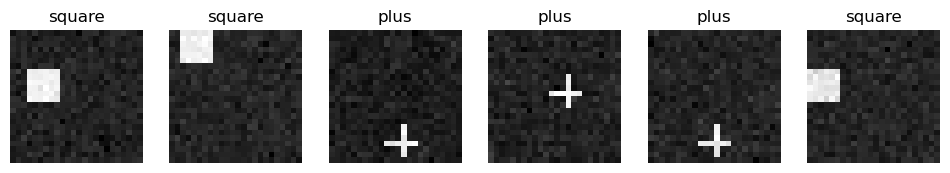

In [15]:
X_train, y_train = make_dataset(n_per_class=30, ox_range=(0, 12), seed=42)                 # shapes in the left region
X_test, y_test = make_dataset(n_per_class=30, ox_range=(14, CANVAS - PATCH + 1), seed=7)  # disjoint right region
print(f"train {len(y_train)} images (x-offset in [0,12)) | test {len(y_test)} images (x-offset in [14,18])")

fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, i in zip(axes, range(6)):
    ax.imshow(X_train[i, 0], cmap="gray"); ax.set_title("plus" if y_train[i, 0] else "square"); ax.axis("off")
plt.show()

## Two models
- **CNN**: `Conv(1→8) → ReLU → MaxPool → Conv(8→16) → ReLU → GlobalMaxPool → Dense`
- **MLP baseline**: `Flatten → Dense(576→64) → ReLU → Dense`

Same data, same optimizer, same init seed.

In [16]:
loss_fn = BCELoss()
EPOCHS, LR = 300, 0.03

np.random.seed(1)
cnn = Model([
    Conv2D(1, 8, 3), ReLU(), MaxPool2D(2),      # 24x24 -> 22x22 -> 11x11
    Conv2D(8, 16, 3), ReLU(), GlobalMaxPool(),  # 11x11 -> 9x9 -> 16 features
    Dense(16, 1), Sigmoid(),
])
train_model(cnn, X_train, y_train, loss_fn, EPOCHS, LR)

np.random.seed(1)
mlp = Model([Flatten(), Dense(CANVAS * CANVAS, 64), ReLU(), Dense(64, 1), Sigmoid()])
train_model(mlp, X_train, y_train, loss_fn, EPOCHS, LR)

acc = {n: (accuracy(m, X_train, y_train), accuracy(m, X_test, y_test)) for n, m in [("CNN (conv + global pool)", cnn), ("MLP (flatten + dense)", mlp)]}
print(f"{'Model':<26}{'Train':<10}{'Test (unseen positions)'}")
for n, (tr, te) in acc.items():
    print(f"{n:<26}{tr:<10.2%}{te:.2%}")

assert acc["CNN (conv + global pool)"][0] > 0.9, "CNN failed to fit training data (check conv/pool forward+backward)"
assert acc["CNN (conv + global pool)"][1] > acc["MLP (flatten + dense)"][1] + 0.1, "CNN did not generalize across positions better than MLP"

Model                     Train     Test (unseen positions)
CNN (conv + global pool)  100.00%   93.33%
MLP (flatten + dense)     100.00%   61.67%


## What the first-layer filters learned

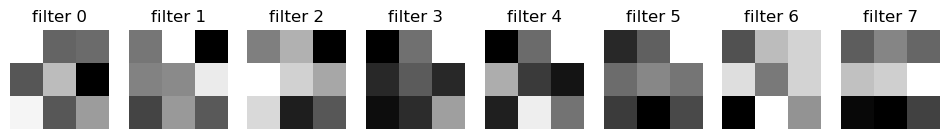

In [17]:
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(cnn.layers[0].weights[i, 0], cmap="gray"); ax.set_title(f"filter {i}"); ax.axis("off")
plt.show()

Both models hit ~100% on the training positions; only the CNN transfers to unseen ones — weight sharing is the whole point.

**Next: `06_rnn_lstm`** — sequences. Images have spatial structure; text/time-series have order, handled with recurrence.